<h2 style="break-before: page; page-break-before: always;">
Q3.1
</h2>

Average Base Classifier Accuracy (Validation): 98.89%
Final Ensemble Accuracy (Validation): 99.50%
Final Ensemble Accuracy (Test): 99.10%


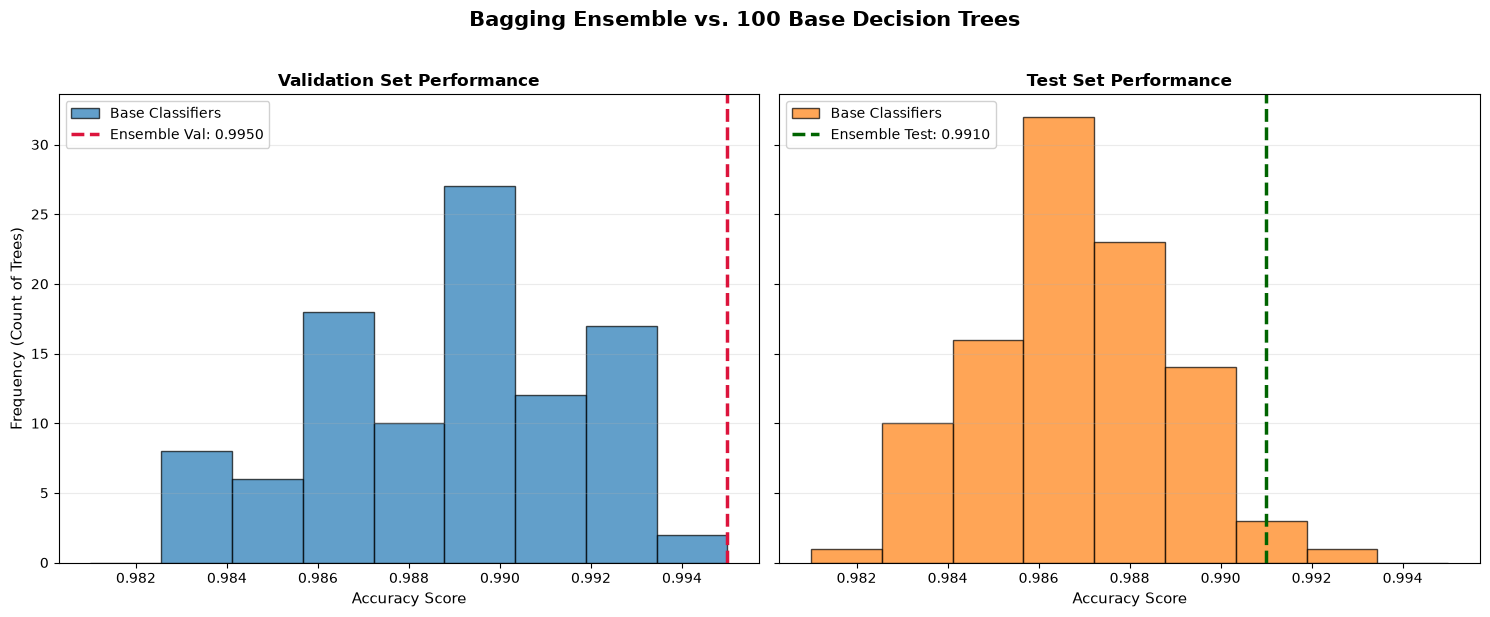

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score
from scipy.stats import mode

# read csv
df = pd.read_csv('A2Q2-troublesome-data.csv', index_col=0,
                 header=0,
                 names=['index', 'x1', 'x2', 'target'])

# seperate features and target/label value
X = df[['x1', 'x2']]
y = df['target']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=123123
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=123123
)

base_val_accs = []
base_test_accs = []
val_preds = []
test_preds = []

## now let's train 100 decision trees on randomized training data
for i in range(100):
    X_sample, y_sample = resample(
        X_train, y_train,
        replace=True,
        n_samples=len(X_train), # match original dataset size
        random_state=i
    )

    # train individual decision tree
    clf = DecisionTreeClassifier(max_depth=None, random_state=i)
    clf.fit(X_sample, y_sample)

    # predict on validation set
    val_pred = clf.predict(X_val)
    val_preds.append(val_pred)

    # predict on test set
    test_pred = clf.predict(X_test)
    test_preds.append(test_pred)

    # add accuracies to list
    base_val_accs.append(accuracy_score(y_val, val_pred))
    base_test_accs.append(accuracy_score(y_test, test_pred))

# take the maximum (majority) vote of base classifier
ensemble_val_pred, _ = mode(np.array(val_preds), axis=0, keepdims=False)
ensemble_test_pred, _ = mode(np.array(test_preds), axis=0, keepdims=False)

# evaluate ensemble performance
ensemble_val_accuracy = accuracy_score(y_val, ensemble_val_pred)
ensemble_test_accuracy = accuracy_score(y_test, ensemble_test_pred)

print(f"Average Base Classifier Accuracy (Validation): {np.mean(base_val_accs) * 100:.2f}%")
print(f"Final Ensemble Accuracy (Validation): {ensemble_val_accuracy * 100:.2f}%")
print(f"Final Ensemble Accuracy (Test): {ensemble_test_accuracy * 100:.2f}%")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Define shared bin ranges to keep scales consistent
all_scores = base_val_accs + base_test_accs + [ensemble_val_accuracy, ensemble_test_accuracy]
min_score, max_score = min(all_scores) , max(all_scores)
custom_bins = np.linspace(min_score, max_score, 10) 

#  validation set subplot 1
ax1.hist(base_val_accs, bins=custom_bins, color='#1f77b4', alpha=0.7, edgecolor='black', label='Base Classifiers')
ax1.axvline(ensemble_val_accuracy, color='crimson', linestyle='dashed', linewidth=2.5, 
            label=f'Ensemble Val: {ensemble_val_accuracy:.4f}')
ax1.set_title('Validation Set Performance', fontsize=12, fontweight='bold')
ax1.set_xlabel('Accuracy Score', fontsize=11)
ax1.set_ylabel('Frequency (Count of Trees)', fontsize=11)
ax1.legend(loc='upper left', framealpha=0.9)
ax1.grid(axis='y', alpha=0.25)

# test set subplot 2
ax2.hist(base_test_accs, bins=custom_bins, color='#ff7f0e', alpha=0.7, edgecolor='black', label='Base Classifiers')
ax2.axvline(ensemble_test_accuracy, color='darkgreen', linestyle='dashed', linewidth=2.5, 
            label=f'Ensemble Test: {ensemble_test_accuracy:.4f}')
ax2.set_title('Test Set Performance', fontsize=12, fontweight='bold')
ax2.set_xlabel('Accuracy Score', fontsize=11)
ax2.legend(loc='upper left', framealpha=0.9)
ax2.grid(axis='y', alpha=0.25)

# Global layout settings
plt.suptitle('Bagging Ensemble vs. 100 Base Decision Trees', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()



<h2 style="break-before: page; page-break-before: always;">
Q3.2
</h2>

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample
from sklearn.metrics import accuracy_score
from scipy.stats import mode

# Define hyperparameter variations to test
experiments = [
    # Baseline
    {"label": "Default (max_depth=None, unconstrained)", "params": {"max_depth": None}},
    
    # effect of Tree Depth
    {"label": "max_depth = 1", "params": {"max_depth": 1}},
    {"label": "max_depth = 2", "params": {"max_depth": 2}},
    {"label": "max_depth = 5", "params": {"max_depth": 5}},
    
    # effect of Node Regularization
    {"label": "min_samples_split = 20", "params": {"min_samples_split": 20}},
    {"label": "min_samples_leaf = 10", "params": {"min_samples_leaf": 10}},
    
    # effect of Splitting Criterion
    {"label": "criterion = 'entropy'", "params": {"criterion": "entropy"}},
]

records = []

for exp in experiments:
    val_preds = []
    test_preds = []
    base_val_accs = []
    
    for i in range(100):
        # Bootstrap sample matching train set size
        X_sample, y_sample = resample(
            X_train, y_train,
            replace=True,
            n_samples=len(X_train),
            random_state=i
        )
        
        clf = DecisionTreeClassifier(**exp["params"], random_state=i)
        clf.fit(X_sample, y_sample)
        
        v_pred = clf.predict(X_val)
        t_pred = clf.predict(X_test)
        
        val_preds.append(v_pred)
        test_preds.append(t_pred)
        base_val_accs.append(accuracy_score(y_val, v_pred))
        
    # Majority vote
    ens_val_pred, _ = mode(np.array(val_preds), axis=0, keepdims=False)
    ens_test_pred, _ = mode(np.array(test_preds), axis=0, keepdims=False)
    
    records.append({
        "Configuration": exp["label"],
        "Avg Base Tree Acc": f"{np.mean(base_val_accs) * 100:.2f}%",
        "Ensemble Val Acc": f"{accuracy_score(y_val, ens_val_pred) * 100:.2f}%",
        "Ensemble Test Acc": f"{accuracy_score(y_test, ens_test_pred) * 100:.2f}%"
    })

# Format and print results
results_df = pd.DataFrame(records)
print(results_df.to_string(index=False))

                          Configuration Avg Base Tree Acc Ensemble Val Acc Ensemble Test Acc
Default (max_depth=None, unconstrained)            98.89%           99.50%            99.10%
                          max_depth = 1            99.07%           99.10%            98.50%
                          max_depth = 2            99.43%           99.50%            99.20%
                          max_depth = 5            99.35%           99.50%            99.20%
                 min_samples_split = 20            99.03%           99.50%            99.20%
                  min_samples_leaf = 10            99.32%           99.50%            99.20%
                  criterion = 'entropy'            98.91%           99.50%            99.20%


<h2 style="break-before: page; page-break-before: always;">
Q3.6
</h2>

In [5]:
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Default AdaBoostClassifier (estimator=None)
ada_default = AdaBoostClassifier(estimator=None, random_state=123123)
ada_default.fit(X_train, y_train)
acc_default = accuracy_score(y_val, ada_default.predict(X_val))

# 2. AdaBoost with default Decision Tree
ada_dt = AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=123123), random_state=123123)
ada_dt.fit(X_train, y_train)
acc_dt = accuracy_score(y_val, ada_dt.predict(X_val))

# 3. AdaBoost with default Random Forest
ada_rf = AdaBoostClassifier(estimator=RandomForestClassifier(random_state=123123), random_state=123123)
ada_rf.fit(X_train, y_train)
acc_rf = accuracy_score(y_val, ada_rf.predict(X_val))

print(f"1. Default AdaBoost Validation Accuracy: {acc_default:.4f}")
print(f"2. Decision Tree AdaBoost Validation Accuracy: {acc_dt:.4f}")
print(f"3. Random Forest AdaBoost Validation Accuracy: {acc_rf:.4f}")

1. Default AdaBoost Validation Accuracy: 0.9920
2. Decision Tree AdaBoost Validation Accuracy: 0.9880
3. Random Forest AdaBoost Validation Accuracy: 0.9950


<h2 style="break-before: page; page-break-before: always;">
Q3.8
</h2>

In [ ]:
import time
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# default AdaBoostClassifier
start = time.time()
ada = AdaBoostClassifier(random_state=123123)
ada.fit(X_train, y_train)
ada_train_time = time.time() - start

# default GradientBoostingClassifier
start = time.time()
gb = GradientBoostingClassifier(random_state=123123)
gb.fit(X_train, y_train)
gb_train_time = time.time() - start

# default XGBoostClassifier
start = time.time()
xgb = XGBClassifier(random_state=123123, eval_metric='logloss')
xgb.fit(X_train, y_train)
xgb_train_time = time.time() - start

# evaluate on Validation and Test Sets
models = [
    ("AdaBoost", ada, ada_train_time),
    ("Gradient Boosting", gb, gb_train_time),
    ("XGBoost", xgb, xgb_train_time)
]

q38_results = []
for name, clf, elapsed in models:
    val_pred = clf.predict(X_val)
    test_pred = clf.predict(X_test)
    q38_results.append({
        "Classifier": name,
        "Validation Accuracy": f"{accuracy_score(y_val, val_pred) * 100:.2f}%",
        "Test Accuracy": f"{accuracy_score(y_test, test_pred) * 100:.2f}%",
        "Training Time (s)": f"{elapsed:.4f}"
    })

q38_df = pd.DataFrame(q38_results)
print(q38_df.to_string(index=False))

                 Classifier Validation Accuracy Test Accuracy Training Time (s)
         AdaBoost (Default)              99.20%        98.60%            0.2166
Gradient Boosting (Default)              99.30%        99.00%            0.6736
          XGBoost (Default)              99.00%        99.00%            1.5271


1. Default AdaBoost Validation Accuracy: 0.9920
2. Decision Tree AdaBoost Validation Accuracy: 0.9880
3. Random Forest AdaBoost Validation Accuracy: 0.9950
